In [1]:
import os
import sys
import time
import random
from functools import partial
from typing import Sequence

# --- JAX, Flax, and Optax ---
import jax
import jax.numpy as jnp
from jax import jit, jvp, vjp, value_and_grad, lax, vmap
from jax.flatten_util import ravel_pytree
import jaxopt
from flax import linen as nn
import optax

# --- NumPy, SciPy, and Plotting ---
import numpy as np
import scipy
import scipy.io as sio
from scipy import sparse
from scipy.linalg import cholesky, LinAlgError
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as colors

# --- Other Third-Party ---
from tqdm import tqdm
from pyDOE import lhs

# --- Local Application Libraries ---
from Crunch.Models.layers import * 
from Crunch.Auxiliary.metrics import relative_l2 
from Crunch.Optimizers.minimize import minimize
from Crunch.Auxiliary.utils import static_options_SSBroyden
# Shorts
Array = jnp.ndarray


## Data Type

We will work with a Second-Order Optimizer so we need to activate double precision

In [2]:
#from jax import config
jax.config.update("jax_enable_x64", True)
# force jax to use one device
os.environ["CUDA_VISIBLE_DEVICES"]="0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"

In [3]:
import argparse
# Set up argument parser
parser = argparse.ArgumentParser(description='Tuning Parameters')
parser.add_argument('--Equation', type=str, default='Allen_Cahn', help='Name of equation')
parser.add_argument('--Name', type=str, default='SS_Broyden', help='Name of the experiment')
parser.add_argument('--NC', type=int, default=200000, help='Number of samples for training')
parser.add_argument('--NI', type=int, default=512, help='Number of iterations')
parser.add_argument('--NB', type=int, default=512, help='Batch size')
parser.add_argument('--NC_TEST', type=int, default=100, help='Number of test samples')
parser.add_argument('--SEED', type=int, default=9999, help='Random seed')
parser.add_argument('--EPOCHS', type=int, default=20000, help='Number of training epochs')
parser.add_argument('--N_LAYERS', type=int, default=3, help='Number of layers in the network')
parser.add_argument('--HIDDEN', type=int, default=30, help='Number of hidden units per layer')
parser.add_argument('--FEATURES', type=int, default=1, help='Feature size')
parser.add_argument('--degree', type=int, default=9, help='Degree of outer')
parser.add_argument('--degree_T', type=int, default=2, help='Degree of polynomial')
parser.add_argument('--lr_fact', type=float, default=0.2, help='Scale Lr')
parser.add_argument('--eta', type=float, default=0.01, help='Learning rate or step size for adaptive gamma')
parser.add_argument('--gamma', type=float, default=0.999, help='Decay rate for adaptive gamma')
parser.add_argument('--gamma_bfgs', type=float, default=0.1, help='Decay rate for adaptive gamma')
parser.add_argument('--gamma_grads', type=float, default=0.99, help='Decay rate for adaptive gamma')
parser.add_argument('--alpha', type=float, default=1.0, help='Decay rate for exponential moving average')
parser.add_argument('--cap_RBA', type=float, default=20, help='Cap limit for RBA')
parser.add_argument('--max_RBA', type=float, help='Maximum RBA value, default calculated as eta / (1 - gamma)')
parser.add_argument('--decay_rate', type=float, default=0.9, help='Decay rate for learning rate schedule')
parser.add_argument('--LR', type=float, default=1e-3, help='Initial learning rate')
parser.add_argument('--decay_step', type=int,default=5000, help='Decay step size')
parser.add_argument('--Note', type=str, default='', help='In case')
parser.add_argument('--batch_size', type=int, default=20000, help='batch_size')
parser.add_argument('--k_samp', type=float, default=1.0, help='Enhance outliers smoothing factor')
parser.add_argument('--c_samp', type=float, default=0.0, help='homogenize')
parser.add_argument('--phi', type=float, default=1, help='Enhance outliers smoothing factor')
parser.add_argument('--c_log', type=float, default=1.0, help='homogenize')
parser.add_argument('--N_change', type=int, default=100, help='homogenize')

# Parse arguments and display them
args, unknown = parser.parse_known_args()
for arg, value in vars(args).items():
    print(f'{arg}: {value}')

# Initialize parameters with parsed or default values
NC = args.NC
NI = args.NI
NB = args.NB
NC_TEST = args.NC_TEST
SEED = args.SEED
EPOCHS = args.EPOCHS
N_LAYERS = args.N_LAYERS
HIDDEN = args.HIDDEN
FEATURES = args.FEATURES
degree = args.degree
degree_T = args.degree_T
eta = args.eta
#RBA Params
gamma = args.gamma
alpha = args.alpha
max_RBA0 = args.max_RBA if args.max_RBA is not None else eta / (1 - gamma)
cap_RBA = args.cap_RBA
# Global weights
gamma_grads=args.gamma_grads
# Optimizer parameters
decay_rate = args.decay_rate
LR = args.LR
lr0 = LR
decay_step = args.decay_step# if args.decay_step is not None else int(EPOCHS * jnp.log(decay_rate) / jnp.log(lrf / lr0))
# vRBA
c_log=args.c_log
phi=args.phi
# Second order_ Sampling
k_samp_bfgs = args.k_samp
c_samp_bfgs = args.c_samp
Nchange = args.N_change
batch_size=args.batch_size
Nbfgs=100000 # Number of SSBroyden BFGs iterations

args.Name=args.Name+f'vRBA-phi:{phi:.2f}-c_log:{c_log:.2f}-bs:{batch_size}_k:{k_samp_bfgs:.2f}_N:{Nchange:.2f}_Seed:{SEED}'+args.Note
print(args.Name)

# random key
key = jax.random.PRNGKey(SEED)
key, subkey = jax.random.split(key, 2)
# Initialize NumPy seed
np.random.seed(SEED)


Equation: Allen_Cahn
Name: SS_Broyden
NC: 200000
NI: 512
NB: 512
NC_TEST: 100
SEED: 9999
EPOCHS: 20000
N_LAYERS: 3
HIDDEN: 30
FEATURES: 1
degree: 9
degree_T: 2
lr_fact: 0.2
eta: 0.01
gamma: 0.999
gamma_bfgs: 0.1
gamma_grads: 0.99
alpha: 1.0
cap_RBA: 20
max_RBA: None
decay_rate: 0.9
LR: 0.001
decay_step: 5000
Note: 
batch_size: 20000
k_samp: 1.0
c_samp: 0.0
phi: 1
c_log: 1.0
N_change: 100
SS_BroydenvRBA-phi:1.00-c_log:1.00-bs:20000_k:1.00_N:100.00_Seed:9999


In [4]:
#Define folder
file_path = os.getcwd()
project_root = os.path.dirname(file_path)
args.Name =project_root+'/Results/'+args.Equation+'/'+args.Name+'/'
os.makedirs(args.Name, exist_ok=True)

# 1. Load/Read/Generate Data

In [5]:
# Load data from the .mat file
data = scipy.io.loadmat('../Data/allen_cahn_HR.mat')
print(data.keys())
Exact = data['usol'].T
Exact0 = np.real(Exact).astype(jnp.float64)  
t0 = data['t'].flatten()[:,None].astype(jnp.float64)     
x0 = data['x'].flatten()[:,None].astype(jnp.float64)    
T, X = np.meshgrid(t0, x0)
# Ground Truth (already float64 due to T, X)
t = T.flatten()[:,None]
x = X.flatten()[:,None]
u_gt = Exact0.flatten()[:,None]

dict_keys(['__header__', '__version__', '__globals__', 't', 'usol', 'x'])


### Training Data preprocesing

In [6]:
# Collocation points
lb_D = jnp.array([t0.min(), x0.min()])
ub_D = jnp.array([t0.max(), x0.max()])
# Generate collocation points and ensure they are float64
X_c = lb_D + (ub_D - lb_D) * lhs(2, NC)
X_c = X_c.astype(jnp.float64) 
tc = X_c[:, 0:1]
xc = X_c[:, 1:2]
# Initial conditions
ti = T[:, 0:1]
xi = X[:, 0:1]
ui = Exact0[:, 0:1]
# Boundary Conditions (not used in the 2nd order part, but good practice)
keys = jax.random.split(key, 13)
tb = jax.random.uniform(keys[3], (NB, 1), minval=lb_D[0], maxval=ub_D[0]).astype(jnp.float64)
# This data tuple is now consistently float64
train_data = tc, xc, ti, xi, ui
lambdas = tc * 0 + 0.1

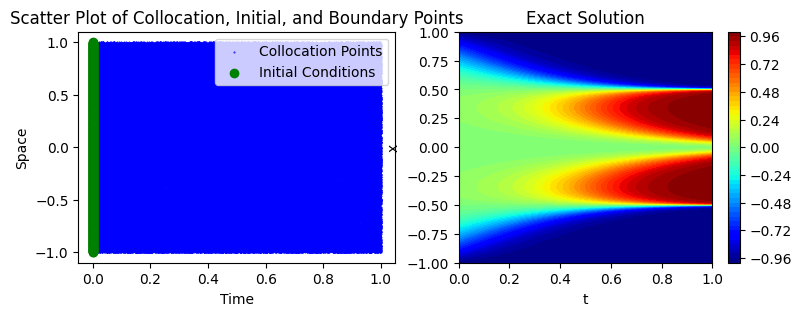

In [7]:
# Plotting code
fig = plt.figure(figsize=(9, 3))
# Scatter plot for collocation, initial, and boundary points
ax1 = fig.add_subplot(121)
ax1.scatter(tc, xc, color='blue', label='Collocation Points',s=0.2)
ax1.scatter(ti, xi, color='green', label='Initial Conditions')
ax1.set_xlabel('Time')
ax1.set_ylabel('Space')
ax1.set_title('Scatter Plot of Collocation, Initial, and Boundary Points')
ax1.legend()

# Surface plot for Exact solution
ax2 = fig.add_subplot(122)
contour = ax2.contourf(T, X, Exact0, cmap='jet', levels=50)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax2.set_xlabel('t')
ax2.set_ylabel('x')
ax2.set_title('Exact Solution')
plt.show()

## 1. PINN Model

In [8]:
class Periodic_Fourier_Features(nn.Module):
    kmax: int = 1
    Lx: float = 2.0 
    @nn.compact
    def __call__(self, X: Array) -> Array:
        ks = jnp.arange(1, self.kmax + 1)
        Xper = 2 * jnp.pi * jnp.matmul(X, ks[None, :]) / self.Lx
        xcos = jnp.cos(Xper)
        xsin = jnp.sin(Xper)
        Xper = jnp.concatenate([xcos, xsin], axis=1)
        return Xper

class MLP(nn.Module):
    features: Sequence[int]
    @nn.compact
    def __call__(self, Z: Array) -> Array:
        init = nn.initializers.glorot_normal()
        for fs in self.features[:-1]:
            Z = nn.Dense(fs, kernel_init=init)(Z)
            Z = nn.activation.tanh(Z)
        Z = nn.Dense(self.features[-1], kernel_init=init)(Z)
        return Z

# forward function
class PINN(nn.Module):
    features: Sequence[int]
    kmax: int = 1     
    Lx: float = 2.0  
    def setup(self):
         self.enbedding = Periodic_Fourier_Features(kmax=self.kmax, Lx=self.Lx)
         self.MLP = MLP(features=self.features)
    @nn.compact
    def __call__(self, t: Array, x: Array) -> Array:
        x_embedded = self.enbedding(x)
        X_concat = jnp.concatenate([t, x_embedded], axis=-1)
        H = self.MLP(X_concat)
        return H

### Initialize Model, parameter and optimizer

In [9]:
feat_sizes = tuple([HIDDEN for _ in range(N_LAYERS)] + [FEATURES])
print(feat_sizes)
# make & init model
model = PINN(feat_sizes)
params = model.init(subkey, jnp.ones((NC, 1), dtype=jnp.float64), jnp.ones((NC, 1), dtype=jnp.float64))
params = jax.tree_util.tree_map(lambda x: x.astype(jnp.float64), params)
optimizers = {}
for key_params in params['params'].keys():
    if key_params=='g_fx':
        optimizers[key_params]=optax.adam(optax.exponential_decay(lr0*args.lr_fact, decay_step, decay_rate, staircase=False))
    else:
        optimizers[key_params]=optax.adam(optax.exponential_decay(lr0, decay_step, decay_rate, staircase=False))
# Initialize optimizer states for each parameter group
states = {key_params: optim.init(params['params'][key_params]) for key_params, optim in optimizers.items()}
# forward & loss function
apply_fn = jax.jit(model.apply)
total_params = sum(x.size for x in jax.tree_util.tree_leaves(params))
print(total_params )

(30, 30, 30, 1)
2011


## Update Functions

### vRBA

In [10]:
def update_vRBA(
    r_i_norm, lambdas_batch, it,
    c_log=1.0, gamma=0.999, eta=0.01, phi=1.0,
    potential_type='exponential'):
    
    if potential_type == 'exponential':
        mu_r = c_log * jnp.max(r_i_norm) / jnp.log(it + 2.0)
        beta_it = 1.0 / (mu_r + 1e-20)
        q_it = beta_it * jnp.exp(beta_it * r_i_norm)
    elif potential_type == 'quadratic':# Standard RBA
        q_it = r_i_norm
    elif potential_type == 'linear': # No weights
        q_it = jnp.ones_like(r_i_norm)
    
    lambda_it = phi * q_it / (q_it.max() + 1e-20) + (1.0 - phi)
    new_lambdas = gamma * lambdas_batch + eta * lambda_it# EMA
    return new_lambdas

In [11]:
METHOD = 'exponential' 
c_log = 1.0 
phi = 1.0

update_fn_with_baked_in_type = partial(
    update_vRBA,
    c_log=c_log,
    phi=phi,
    potential_type=METHOD
)
update_weights_fn = jax.jit(update_fn_with_baked_in_type)

### Parameters

In [12]:
@partial(jax.jit, static_argnums=(0, 1))  # key and optimizer are static
def update_model(key_params, optimizer, gradient, params, state):
    updates, new_state = optimizer.update(gradient['params'][key_params], state)
    new_params = optax.apply_updates(params['params'][key_params], updates)
    params['params'][key_params] = new_params
    return params, new_state


## Equations

In [13]:
def Allen_Cahn(params, t, x, apply_fn):
    u = apply_fn(params, t, x)
    v_t = jnp.ones_like(t)
    v_x = jnp.ones_like(x)
    ut = jvp(lambda t_val: apply_fn(params, t_val, x), (t,), (v_t,))[1]
    uxx = hvp_fwdfwd(lambda x_val: apply_fn(params, t, x_val), (x,), (v_x,))
    return ut - 0.0001 * uxx + 5.0 * u ** 3 - 5.0 * u

PDE_residuals=Allen_Cahn

## Training

In [14]:
@partial(jax.jit, static_argnums=(0, 1))
def apply_model(
    apply_fn,
    update_weights_fn,     
    params, lambdas, lamB, 
    all_grads,  # ❗️ 1. ADD THIS BACK IN
    idx_train, it,
    hyperparams,    
    *train_data
):
    lamE,gamma, eta, gamma_grads, alpha = hyperparams
    t, x, ti, xi, ui = train_data
    lambdas_it = lambdas[idx_train]

    def loss_pde(params, lambdas):
        residuals = PDE_residuals(params, t, x, apply_fn) 
        r_i_norm = lax.stop_gradient(jnp.abs(residuals))
        new_lambdas = update_weights_fn(r_i_norm,lambdas, it, 
                                          gamma=gamma,
                                          eta=eta)
        pde_loss = jnp.mean((new_lambdas * residuals) ** 2)
        return pde_loss, new_lambdas

    def loss_bcs(params):
        u_pred = apply_fn(params, ti, xi)
        ics_loss = jnp.mean((ui - u_pred) ** 2)
        return ics_loss

    (pde_loss, new_lambdas), gradient_pde = jax.value_and_grad(loss_pde, has_aux=True)(params, lambdas_it)
    ics_loss, gradient_bcs = jax.value_and_grad(loss_bcs)(params)
    lambdas = lambdas.at[idx_train].set(new_lambdas)
    pde_gradient_flat, _ = ravel_pytree(gradient_pde)
    bcs_gradient_flat, _ = ravel_pytree(gradient_bcs)
    grad_PDE_norm = jnp.linalg.norm(pde_gradient_flat) + 1e-20
    grad_bcs_norm = jnp.linalg.norm(bcs_gradient_flat) + 1e-20
    
    # This line now correctly uses the 'all_grads' that was passed in
    grad_avg_PDE = gamma_grads * all_grads['grad_bar_PDE'] + (1.0 - gamma_grads) * grad_PDE_norm
    grad_avg_BCs = gamma_grads * all_grads['grad_bar_BCs'] + (1.0 - gamma_grads) * grad_bcs_norm
    
    lamB = alpha * lamB + (1.0 - alpha) * grad_avg_PDE / (grad_avg_BCs + 1e-20)
    total_gradient = jax.tree_util.tree_map(lambda g_pde, g_bcs: lamE * g_pde + lamB * g_bcs, gradient_pde, gradient_bcs)
    
    all_loss = {
        'loss_PDE': pde_loss,
        'loss_BCs': ics_loss,
        'Loss': lamE * pde_loss + lamB * ics_loss,
    }    
    all_grads_updated = {
        'grad_bar_PDE': grad_avg_PDE,
        'grad_bar_BCs': grad_avg_BCs,
    }
    
    return all_loss, total_gradient, lambdas, lamB, all_grads_updated

## Update Loop

In [15]:
def get_gamma(eta, max_RBA):
    gamma_it = 1-eta/max_RBA
    return gamma_it

In [16]:
@partial(jax.jit, static_argnames=("batch_size", "k", "c"))
def sample_points_pdf(key, batch_size, lambdas, tc, xc, ti, xi, ui, k=1, c=0.5):
    """
    Samples collocation points based on a probability distribution derived
    from 'lambdas' (adaptive weights).
    """
    # Adjust lambdas with exponent k and normalize
    lambdas_k = lambdas**k
    lambdas_k = lambdas_k / (lambdas_k.mean() + 1e-20) + c # Added epsilon

    # Ensure the probabilities array is 1D
    lambdas_k = lambdas_k.flatten()
    p = lambdas_k / (lambdas_k.sum() + 1e-20) # Added epsilon

    # Sample indices according to the probability distribution
    idx_train = jax.random.choice(
        key, len(lambdas), shape=(batch_size,), p=p
    )
    
    # Create the training data tuple
    train_data = (tc[idx_train], xc[idx_train], ti, xi, ui)
    
    return idx_train, train_data

In [18]:
all_errors = []
all_L_infty = []
all_L_2 = []
all_its = []
all_loss = []
all_gamma = []
all_lamB = []
all_max_RBA = []
all_lambdas=[]
all_idx=[]

start = time.time()
pbar = tqdm(range(1, EPOCHS + 1), desc='Training Progress')
gamma_it=get_gamma(eta, max_RBA0)
#Global weights
max_RBA=max_RBA0
lamE,lamB=1,max_RBA**2
#RBA
step_RBA=(cap_RBA-max_RBA0)/(EPOCHS/50000-1)
# initialize grads container
all_grads={
    'grad_bar_PDE':1,
    'grad_bar_BCs':1,
}
for e in pbar:
    key, subkey = jax.random.split(key)
    idx_train, train_data = sample_points_pdf(
        subkey, batch_size, lambdas, tc, xc, ti, xi, ui, k=args.k_samp, c=args.c_samp
    )
    # single run
    hyperparams = (lamE,gamma_it, eta, gamma_grads, alpha)
    all_loss_it, gradient, lambdas, lamB, all_grads = apply_model(
            apply_fn, update_weights_fn,
            params, lambdas,
            lamB,
            all_grads,
            idx_train,
            e,                
            hyperparams,  
            *train_data
        )

    for key_params in params['params']:
        params, states[key_params] = update_model(key_params, optimizers[key_params], gradient, params, states[key_params])
    log_frequency = 1 if e < 500 else 100 if e <= 5000 else 500
    if e % log_frequency == 0:
        # Update RBA
        max_RBA=max_RBA0+step_RBA*e//50000
        gamma_it=get_gamma(eta, max_RBA)
        all_lambdas.append(np.array(lambdas))  #
        all_idx.append(idx_train)
        #Compute errors
        u_pred_it=apply_fn(params, t, x)
        error = relative_l2(u_pred_it, u_gt)
        error_vec = u_pred_it - u_gt
        L_infty = scipy.linalg.norm(error_vec.flatten(), ord=np.inf)
        L_2 = scipy.linalg.norm(error_vec.flatten(), ord=2)
        # Updating the tqdm progress bar with loss and other metrics
        pbar.set_description(f"It: {e}/{EPOCHS} | Error: {error:.3e} | lam_max: {lambdas.max():.3f}| max_RBA: {max_RBA:.3f}| lamB: {lamB:.3f}|")
        all_errors.append(error)
        all_its.append(e)
        all_lambdas.append(np.array(lambdas))
        all_loss.append(all_loss_it['Loss'])
        all_gamma.append(gamma_it)
        all_lamB.append(lamB)
        all_max_RBA.append(max_RBA)
        # Error norms
        all_L_infty.append(L_infty)
        all_L_2.append(L_2)
end = time.time()
print(f'Runtime: {((end - start) / EPOCHS * 1000):.2f} ms/iter.')

It: 20000/20000 | Error: 4.891e-01 | lam_max: 1.956| max_RBA: 3.000| lamB: 100.000|: 100%|██████████| 20000/20000 [00:43<00:00, 463.43it/s]

Runtime: 2.16 ms/iter.


# Errors


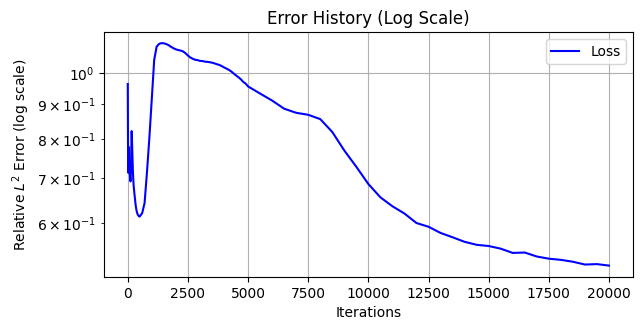

In [ ]:
# Adjusting the plot to use a log scale for both loss and error
plt.figure(figsize=(12, 6))
# Plotting loss history with log scale
plt.subplot(2, 2, 1)
plt.plot(all_its, all_errors, label='Loss', color='blue')
plt.yscale('log')
plt.xlabel('Iterations')
plt.ylabel('Relative $L^2$ Error (log scale)')
plt.title('Error History (Log Scale)')
plt.grid(True)
plt.legend()

# Show the plots
plt.tight_layout()
plt.savefig(args.Name+'_Loss.png')
plt.show()


In [ ]:
error = relative_l2(apply_fn(params, t, x), u_gt)
print(f'RL2 error: {error:.8f}') 

RL2 error: 0.51952836


Solution:


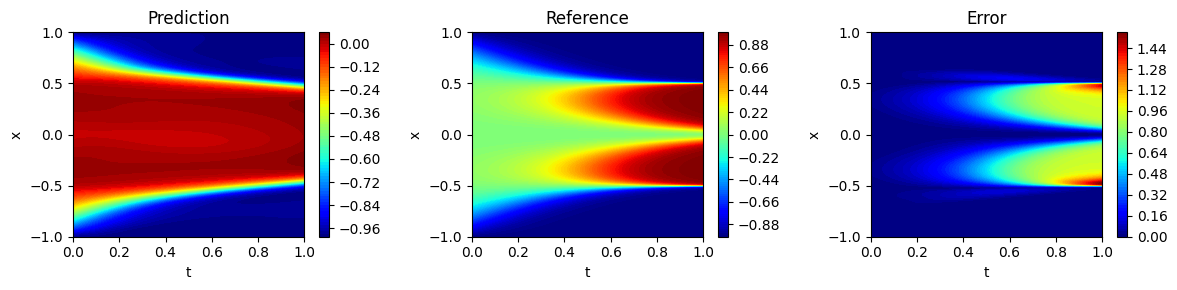

In [ ]:
it=-1
print('Solution:')
u = apply_fn(params, t, x)
u = u.reshape(T.shape)
lambdas_grid=all_lambdas[it]
idx_it=all_idx[it]

# Plotting code
fig = plt.figure(figsize=(12, 3))
levels=100
# Scatter plot for collocation, initial, and boundary points
ax1 = fig.add_subplot(131)
contour = ax1.contourf(T, X, u, cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax1.set_xlabel('t')
ax1.set_ylabel('x')
ax1.set_title('Prediction')

# Surface plot for Exact solution
ax2 = fig.add_subplot(132)
contour = ax2.contourf(T, X, Exact0, cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax2.set_xlabel('t')
ax2.set_ylabel('x')
ax2.set_title('Reference')
# Surface plot for Exact solution
ax3 = fig.add_subplot(133)
contour = ax3.contourf(T, X, np.abs(Exact0-u), cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax3.set_xlabel('t')
ax3.set_ylabel('x')
ax3.set_title('Error')
plt.tight_layout()

plt.savefig(args.Name+'Errorss_RBA-R.png',dpi=300)
plt.show()

# Second Order Optimization (Custom SSBRoyden)

#### Initialization and Hyperparameters

In [ ]:
gamma = args.gamma_bfgs
eta = 1-gamma
initial_weights, unflatten_func = ravel_pytree(params)
params_test=unflatten_func(initial_weights)
error = relative_l2(apply_fn(params, t, x), u_gt)
print(f'RL2 error: {error:.8f}') 
error = relative_l2(apply_fn(params_test, t, x), u_gt)
print(f'Reconstructed parameters: RL2 error: {error:.8f}') 
X=np.hstack([tc.astype(jnp.float64),xc.astype(jnp.float64)])

RL2 error: 0.51952836
Reconstructed parameters: RL2 error: 0.51952836


## New Update rule

In [ ]:
@partial(jax.jit, static_argnums=(0,))
def apply_model_2nd_Order(apply_fn, params, *train_data):
    t, x, ti, xi, ui = train_data
    def loss_pde(params):
        # Compute residuals
        residuals = PDE_residuals(params, t, x, apply_fn)
        pde_loss = jnp.mean((residuals)**2)
        return pde_loss
    def loss_bcs(params):
        # Compute initial condition loss
        u_pred = apply_fn(params, ti, xi)
        ics_loss = jnp.mean((ui - u_pred) ** 2)
        return ics_loss
    def loss(params):
        return loss_pde(params)+10.0*loss_bcs(params)
    loss_value=loss(params)
    return loss_value

In [ ]:
@partial(jax.jit, static_argnums=(0,))
def update_lambdas(apply_fn,params,lambdas,gamma,eta,tc,xc,it):
    t,x=tc,xc
    def get_lambdas(params, lambdas):
        residuals = PDE_residuals(params, t, x, apply_fn)
        # Update lambdas
        r_i_norm = lax.stop_gradient(jnp.abs(residuals))
        new_lambdas = update_weights_fn(r_i_norm,lambdas, it, 
                                          gamma=gamma,
                                          eta=eta)
        return new_lambdas
    new_lambdas=get_lambdas(params, lambdas)
    return new_lambdas

In [ ]:
@partial(jax.jit, static_argnums=(1, 2))
def loss_and_gradient(weights, N_arg, unflatten_func_arg, *train_data_tuple_arg):
    flat_jax_array = weights 
    params_current = unflatten_func_arg(flat_jax_array)
    loss_val_jax = apply_model_2nd_Order(N_arg, params_current, *train_data_tuple_arg)
    return loss_val_jax

In [ ]:

@partial(jax.jit, static_argnames=("apply_fn", "unflatten_func", "batch_size", "gamma", "eta", "k", "c", "static_options"))
def SSBroyden_step(
    initial_weights, H0, key,
    tc, xc, lambdas,
    apply_fn, unflatten_func, batch_size, gamma, eta, k, c, static_options,it,
    ti, xi, ui ):
    key, subkey = jax.random.split(key)
    # 2. Update Lambdas ...
    params_it = unflatten_func(initial_weights)
    updated_lambdas = update_lambdas(apply_fn, params_it, lambdas, gamma, eta, tc, xc,it)
    _ , current_train_data_tuple = sample_points_pdf(
        subkey, batch_size, updated_lambdas, tc, xc, ti, xi, ui, k, c
    )
    # 4. Prepare the full options dictionary for minimize
    current_options = dict(static_options)
    current_options['initial_H'] = H0
    # 5. Run the SSBroyden optimization for Nchange steps
    result = minimize(
        fun=loss_and_gradient,
        x0=initial_weights,
        args=(apply_fn, unflatten_func, *current_train_data_tuple),
        method='BFGS', # SSBroyden version of BFGs
        options=current_options)
    # 6. Recycle the Hessian purely
    new_H0 = result.hess_inv
    new_H0 = (new_H0 + jnp.transpose(new_H0)) / 2
    try:
        L = jnp.linalg.cholesky(new_H0)
        is_failed = jnp.any(jnp.isnan(L))
        final_H0 = jax.lax.cond(
            is_failed,
            lambda op: jnp.eye(op.shape[0], dtype=op.dtype),
            lambda op: op,
            operand=new_H0)
    except LinAlgError:
        final_H0 = jnp.eye(new_H0.shape[0], dtype=new_H0.dtype)
    return result.x, final_H0, key, result.fun, result.nit, updated_lambdas

In [ ]:
# Initialize the Hessian
H0 = jnp.eye(len(initial_weights), dtype=jnp.float64)
num_outer_iterations = Nbfgs // Nchange
## SSBroyden Hyperparameters
static_options = static_options_SSBroyden
static_options['maxiter']=Nchange
static_options_tuple = tuple(static_options.items())
# Training
pbar = tqdm(range(num_outer_iterations), desc="SSBroyden Training")
effective_steps=0
Adam_Steps=all_its[-1]
for it in pbar:
    initial_weights, H0, key, loss_val, nit, lambdas = SSBroyden_step(
        initial_weights, H0, key,
        tc, xc, lambdas,
        apply_fn, unflatten_func, batch_size, gamma, eta, k_samp_bfgs, c_samp_bfgs,
        static_options_tuple,it,
        ti, xi, ui
    )
    effective_steps=effective_steps+nit
    current_params_for_eval = unflatten_func(initial_weights)
    u_pred_it=apply_fn(current_params_for_eval, t, x)
    error = relative_l2(u_pred_it, u_gt)
    error_vec = u_pred_it - u_gt
    L_infty = scipy.linalg.norm(error_vec.flatten(), ord=np.inf)
    L_2 = scipy.linalg.norm(error_vec.flatten(), ord=2)
    all_errors.append(error)
    all_loss.append(loss_val)
    all_its.append(effective_steps+Adam_Steps)
    all_L_infty.append(L_infty)
    all_L_2.append(L_2)
    pbar.set_postfix({
        'It': effective_steps,
        'Loss': f'{loss_val:.3e}',
        'RL2': f'{float(error):.3e}',
        'lam_min': f'{jnp.min(lambdas):.3e}',
        'lam_max': f'{jnp.max(lambdas):.3e}',
    }) 

SSBroyden Training: 100%|██████████| 1000/1000 [02:15<00:00,  7.39it/s, It=61591, Loss=1.915e-11, RL2=3.269e-06, lam_min=9.992e-04, lam_max=9.008e-01]


In [ ]:
T, X = np.meshgrid(t0, x0)
# Ground Truth (already float64 due to T, X)
t = T.flatten()[:,None]
x = X.flatten()[:,None]
u_gt = Exact0.flatten()[:,None]
it=-1
print('Solution:')
u = apply_fn(current_params_for_eval, t, x)
u = u.reshape(T.shape)

Solution:


Solution:


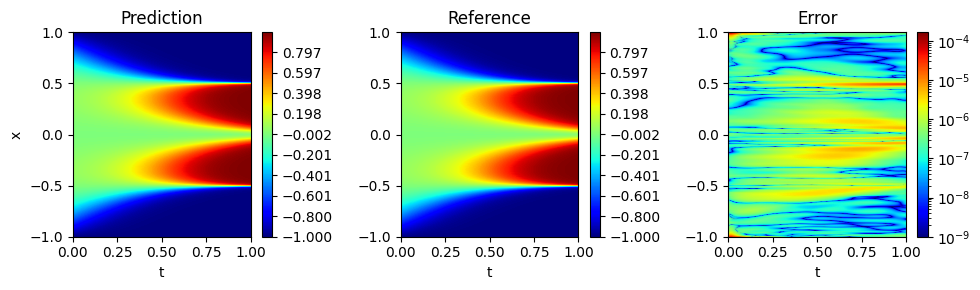

In [ ]:
it=-1
print('Solution:')
# --- 1. Find the global vmin and vmax across BOTH datasets ---
global_vmin = np.min([u, Exact0])
global_vmax = np.max([u, Exact0])
# --- 2. Create a shared array of contour levels ---
# This is the key change that guarantees the colorbars are identical.
num_levels = 500
shared_levels = np.linspace(global_vmin, global_vmax, num_levels)
# Plotting code
fig = plt.figure(figsize=(10, 3))
# --- Plot for Prediction (using the shared levels array) ---
ax1 = fig.add_subplot(131)
contour1 = ax1.contourf(T, X, u, cmap='jet', 
                        levels=shared_levels) # <-- Use the shared levels array
fig.colorbar(contour1, ax=ax1)
ax1.set_xlabel('t')
ax1.set_ylabel('x')
ax1.set_title('Prediction')
# --- Plot for Reference Solution (using the shared levels array) ---
ax2 = fig.add_subplot(132)
contour2 = ax2.contourf(T, X, Exact0, cmap='jet', 
                        levels=shared_levels) # <-- Use the shared levels array
fig.colorbar(contour2, ax=ax2)
ax2.set_xlabel('t')
#ax2.set_ylabel('x')
ax2.set_title('Reference')
# --- Plot for Error (this part is separate and correct) ---
ax3 = fig.add_subplot(133)
error_data = np.abs(Exact0-u)
log_norm = colors.LogNorm(vmin=1e-9, vmax=error_data.max())

mesh3 = ax3.pcolormesh(T, X, error_data, 
                       cmap='jet', 
                       norm=log_norm,
                       shading='gouraud')
fig.colorbar(mesh3, ax=ax3)
ax3.set_xlabel('t')
ax3.set_title('Error')

plt.tight_layout()
plt.savefig(args.Name+'Errors_RBA_SSBroyden.png',dpi=300)
plt.show()

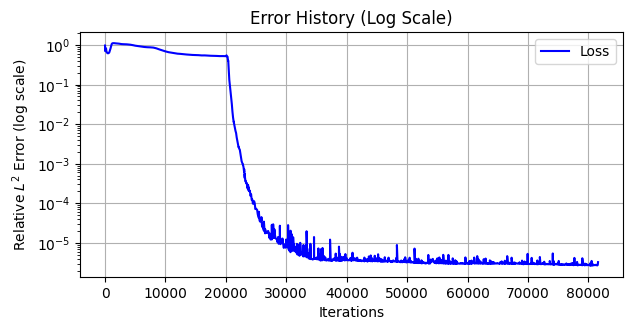

In [ ]:
# Adjusting the plot to use a log scale for both loss and error

plt.figure(figsize=(12, 6))

# Plotting loss history with log scale
plt.subplot(2, 2, 1)
plt.plot(all_its, all_errors, label='Loss', color='blue')


#plt.xscale('log')
plt.yscale('log')
plt.xlabel('Iterations')
plt.ylabel('Relative $L^2$ Error (log scale)')
plt.title('Error History (Log Scale)')
plt.grid(True)
plt.legend()
# Show the plots
plt.tight_layout()
plt.savefig(args.Name+'_Loss.png')
plt.show()


In [ ]:
print('Minimum achieved error:',np.nanmin(all_errors))

Minimum achieved error: 2.6707230627774345e-06


In [ ]:
results_dict = {
    'model_name': args.Name,
    'all_errors': all_errors,
    'all_its': all_its,
    'all_loss': all_loss,
    'all_gamma': all_gamma,
    'all_lamB': all_lamB,
    'all_max_RBA': all_max_RBA,
    'all_L_infty':all_L_infty,
    'all_L_2':all_L_2,
}
# Save dictionary as a .mat file
scipy.io.savemat(args.Name + 'Log_files_SSBroyden.mat', results_dict)